# Car Breakdown Prediction

## AI Project

In deze notebook maak ik een eenvoudig classificatiemodel om te voorspellen of een voertuig binnen 30 dagen een panne zal hebben.  
Ik houd de aanpak bewust simpel: eerst de data kort bekijken, daarna de data voorbereiden, het model trainen en tenslotte een submission-bestand maken.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Data inladen

Eerst laad ik de trainingsdata in. Daarna bekijk ik kort de vorm van de dataset en de kolommen.

In [34]:
train = pd.read_csv("../train_CarBreakDown.csv")
print("Shape of dataset:", train.shape)
print()

print("Column names:")
print(train.columns)
print()

print("Data types:")
print(train.dtypes)

Shape of dataset: (1050, 14)

Column names:
Index(['id', 'vehicle_brand', 'vehicle_age_years', 'mileage_km',
       'engine_hours', 'last_service_km_ago', 'oil_quality_pct',
       'avg_trip_length_km', 'weather_exposure', 'fuel_type',
       'cleanliness_score', 'driver_satisfaction_score', 'tyre_type',
       'breakdown_next_30_days'],
      dtype='str')

Data types:
id                             int64
vehicle_brand                    str
vehicle_age_years            float64
mileage_km                   float64
engine_hours                 float64
last_service_km_ago          float64
oil_quality_pct              float64
avg_trip_length_km           float64
weather_exposure                 str
fuel_type                        str
cleanliness_score            float64
driver_satisfaction_score    float64
tyre_type                        str
breakdown_next_30_days         int64
dtype: object


## 2. Korte verkenning van de data

Ik kijk eerst naar de verdeling van de targetvariabele. Zo zie ik meteen dat de klassen niet perfect in balans zijn.

In [37]:
train["breakdown_next_30_days"].value_counts()

breakdown_next_30_days
0    874
1    176
Name: count, dtype: int64

In [38]:
train["breakdown_next_30_days"].value_counts(normalize=True) * 100

breakdown_next_30_days
0    83.238095
1    16.761905
Name: proportion, dtype: float64

De verdeling hieronder laat dat visueel zien.

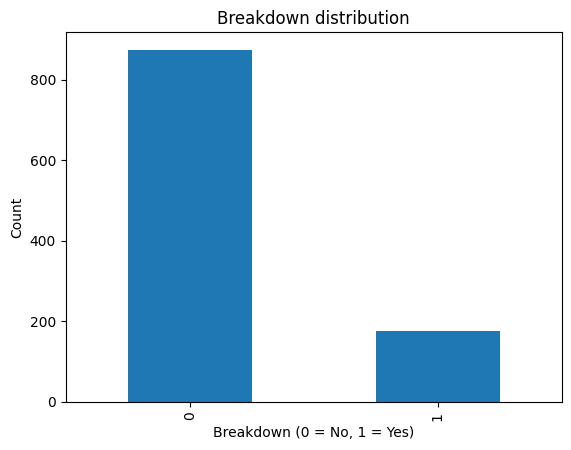

In [39]:
train["breakdown_next_30_days"].value_counts().plot(kind="bar")

plt.title("Breakdown distribution")
plt.xlabel("Breakdown (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

Ik controleer ook kort of er ontbrekende waarden of duplicaten zijn.

In [35]:
print("Missing values per column:")
print(train.isnull().sum())

Missing values per column:
id                            0
vehicle_brand                21
vehicle_age_years            16
mileage_km                   17
engine_hours                 15
last_service_km_ago          10
oil_quality_pct              36
avg_trip_length_km           12
weather_exposure             13
fuel_type                    14
cleanliness_score            55
driver_satisfaction_score    13
tyre_type                    17
breakdown_next_30_days        0
dtype: int64


In [36]:
print("Number of duplicate rows:", train.duplicated().sum())

Number of duplicate rows: 0


## 3. Data voorbereiden

Voor het model gebruik ik alle kolommen behalve `id` en de target.  
Categorische variabelen zet ik om met `get_dummies()`, zodat het model ermee kan werken.

In [54]:
X = train.drop(["id", "breakdown_next_30_days"], axis=1)
y = train["breakdown_next_30_days"]

X = pd.get_dummies(X)

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (1050, 30)
Shape of y: (1050,)


## 4. Train/validation split

Ik werk met de **80/20-regel**:
- 80% van de data om te trainen
- 20% van de data om te valideren

Ik gebruik ook `stratify=y`, zodat de verdeling van 0 en 1 mooi behouden blijft in beide delen.

In [56]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (840, 30)
X_val shape: (210, 30)
y_train shape: (840,)
y_val shape: (210,)


## 5. Model trainen

Volgens de theorie gebruik ik hier een **Random Forest Classifier**.  
Dat model is sterk genoeg als baseline en kan goed omgaan met verschillende soorten features.

In [57]:
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42
)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## 6. Model evalueren

Ik evalueer het model op de validatieset.  
Belangrijk: ik gebruik hier een threshold van **0.45** in plaats van 0.50, omdat dat in deze oefening betere resultaten gaf.

In [58]:
val_probs = model.predict_proba(X_val)[:, 1]
val_predictions = (val_probs >= 0.45).astype(int)

print("Accuracy:", accuracy_score(y_val, val_predictions))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, val_predictions))

Accuracy: 0.8333333333333334

Confusion matrix:
[[173   2]
 [ 33   2]]


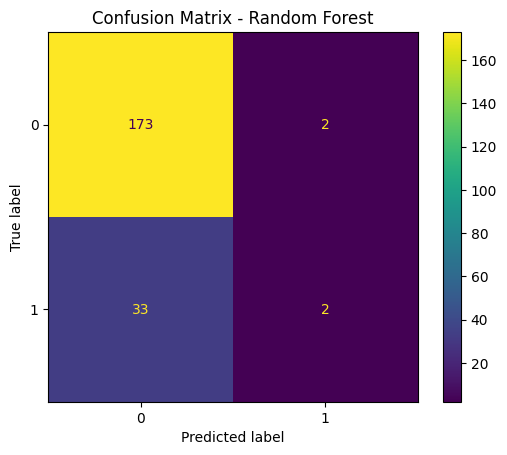

In [59]:
cm = confusion_matrix(y_val, val_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

De confusion matrix toont hoeveel voorspellingen juist en fout zijn.  
Zo kan ik beter zien of het model ook de klasse `1` voldoende oppikt.

## 7. Testdata inladen en voorbereiden

De testset bevat geen targetkolom, dus die gebruik ik om de uiteindelijke voorspellingen te maken.  
Ik bewaar de `id` apart voor het submission-bestand.

In [60]:
test = pd.read_csv("../test_CarBreakDown.csv")
test.head()

,id,vehicle_brand,vehicle_age_years,mileage_km,engine_hours,last_service_km_ago,oil_quality_pct,avg_trip_length_km,weather_exposure,fuel_type,cleanliness_score,driver_satisfaction_score,tyre_type
0,1356,Volkswagen,11.0,227101.296523,7111.496798,31877.398870,45.316195,11.303376,medium,petrol,86.002184,6.789866,winter
1,889,Kia,5.0,131740.074640,4384.690626,24086.715660,55.920468,21.079253,high,petrol,99.964621,9.780574,winter
2,1190,Hyundai,20.0,172283.708707,5997.321760,1087.406667,69.344516,2.827233,medium,diesel,NaN,6.525088,summer
3,122,Toyota,14.0,125092.331956,3710.026613,6919.769411,55.607730,15.947450,NaN,diesel,82.986605,5.850790,all-season
4,1101,Ford,19.0,207068.220620,7152.178785,8102.143623,78.170298,31.696566,low,electric,92.119900,7.954186,summer


In [61]:
test_ids = test["id"]

test_features = test.drop("id", axis=1)
test_features = pd.get_dummies(test_features)
test_features = test_features.reindex(columns=X.columns, fill_value=0)

print("Shape of test features:", test_features.shape)

Shape of test features: (450, 30)


## 8. Voorspellingen maken op de testset

Hier gebruik ik opnieuw de kansvoorspellingen van het model.  
Voor de testset neem ik een threshold van **0.44**.

In [62]:
test_probs = model.predict_proba(test_features)[:, 1]
test_predictions = (test_probs >= 0.44).astype(int)

## 9. Submission-bestand maken

Tot slot maak ik een dataframe met `id` en de voorspelde targetkolom.  
Dat bestand kan ik indienen voor de challenge.

In [63]:
submission = pd.DataFrame({
    "id": test_ids,
    "breakdown_next_30_days": test_predictions
})

submission.head()

,id,breakdown_next_30_days
0,1356,0
1,889,0
2,1190,0
3,122,0
4,1101,0


In [64]:
submission.to_csv("submission.csv", index=False)
print("submission.csv has been created.")

submission.csv has been created.


## 10. Conclusie

Met deze notebook heb ik op een eenvoudige manier een model gebouwd voor de car breakdown challenge.

Wat ik gedaan heb:
- data ingeladen en kort verkend
- features voorbereid met `get_dummies()`
- de data opgesplitst volgens de 80/20-regel
- een Random Forest getraind
- het model geëvalueerd
- voorspellingen gemaakt voor de testset
- een submission-bestand aangemaakt

Ik heb de notebook bewust simpel gehouden, maar wel werkend en logisch opgebouwd volgens de theorie.

## 11. Gebruik van GenAI

GenAI werd enkel gebruikt als hulpmiddel om de structuur en uitleg van de notebook te verbeteren.  
De uiteindelijke keuzes voor preprocessing, threshold en modelopbouw zijn bewust behouden omdat ze werkten voor deze opdracht.